In [1]:
!pip install --upgrade binance-historical-data plotly -q
!pip install requests

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 37.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 272.8/272.8 kB 23.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 48.6 MB/s eta 0:00:00


In [2]:
import os
import warnings
import numpy as np
import pandas as pd
from binance_historical_data import BinanceDataDumper
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from datetime import datetime, timedelta, date, time
warnings.filterwarnings('ignore')

In [3]:
def get_list_all_trading_pairs():
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency="1h",
    )
    return data_dumper.get_list_all_trading_pairs()

def filter_usdt_tickers(tickers):
    exclude_keywords = ["UPUSDT", "DOWNUSDT", "BEARUSDT", "BULLUSDT"]
    return [ticker for ticker in tickers if ticker.endswith("USDT") and not any(ex in ticker for ex in exclude_keywords)]

def find_first_data_date(ticker):
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency="1h",
    )
    return data_dumper.get_min_start_date_for_ticker(ticker)

def format_time(seconds):
    hours = int(seconds // 3600)
    minutes = int((seconds % 3600) // 60)
    secs = int(seconds % 60)
    return f"{hours:02d}:{minutes:02d}:{secs:02d}"

def detect_timestamp_unit(timestamp):
    num_digits = len(str(timestamp))
    if num_digits == 13:
        return 'ms'
    elif num_digits == 16:
        return 'us'
    else:
        raise ValueError(f"Timestamp không hợp lệ: {timestamp}")

def convert_timestamp(timestamp):
    unit = detect_timestamp_unit(timestamp)
    return pd.to_datetime(timestamp, unit=unit, errors='coerce')

def download_ticker(ticker, date_start, date_end, data_frequency="1h"):
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency= data_frequency,
    )
    date_start = datetime.strptime(date_start, "%Y-%m-%d").date()
    date_end = datetime.strptime(date_end, "%Y-%m-%d").date()
    data_dumper.dump_data(
        tickers = ticker,
        date_start = date_start,
        date_end = date_end,
        is_to_update_existing = False,
    )

def read_csv_file(file_path):
    df = pd.read_csv(file_path)
    df.columns = [
        "open_time", "Open", "High", "Low", "Close", "volume",
        "close_time", "quote_asset_volume", "number_of_trades",
        "taker_buy_base_asset_volume", "taker_buy_quote_asset_volume", "ignore"
    ]
    df['open_time'] = df['open_time'].apply(convert_timestamp)
    df['close_time'] = df['close_time'].apply(convert_timestamp)
    return df

def get_csv_files(directory):
    try:
        if not os.path.exists(directory):
            print(f"Warning: Thư mục không tồn tại: {directory}")
            return []
        return [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith('.csv')]
    except Exception as e:
        print(f"Lỗi khi đọc thư mục {directory}: {str(e)}")
        return []

# Load data from file
def process_csv_files(ticker, data_frequency = "1h"):
    daily_path = os.path.join(os.getcwd(), f"spot/daily/klines/{ticker}/{data_frequency}")
    monthly_path = os.path.join(os.getcwd(), f"spot/monthly/klines/{ticker}/{data_frequency}")
    daily_files = get_csv_files(daily_path)
    monthly_files = get_csv_files(monthly_path)
    all_files = daily_files + monthly_files
    if not all_files:
        print(f"❗ Không có file CSV nào cho {ticker}")
        return None
    data = pd.concat([read_csv_file(file) for file in all_files], ignore_index=True)
    data.sort_values(by='open_time', inplace=True)
    return data


In [33]:
data_frequency = "1m"
start_date = "2025-06-27"
end_date = "2025-07-01"
tickers =['ETCUSDT', 'ETHUSDT']


In [34]:
data = pd.DataFrame()
download_ticker(tickers[0], start_date, end_date, data_frequency)
crypto_data = process_csv_files(tickers[0], data_frequency)
data = crypto_data[['open_time','Close']]
data.columns = ['open_time',tickers[0]]
data.set_index('open_time', inplace=True)
data


---> Found overall tickers: 594
---> Filter to asked tickers: 7
------> Tickers left: 2
Download full data for 2 tickers: 
---> Data will be saved here: /content/spot
---> Data Frequency: 1m
---> Start Date: 20250627
---> End Date: 20250701


Tickers:   0%|          | 0/2 [00:00<?, ?it/s]

monthly files to download:   0%|          | 0/1 [00:00<?, ?files/s]

daily files to download:   0%|          | 0/1 [00:00<?, ?files/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

Tried to dump data for 2 tickers:
---> For ETCUSDT new data saved for: 1 months 1 days
---> For ETCUSD new data saved for: 0 months 0 days


,ETCUSDT
open_time,
2025-06-01 00:01:00,16.91
2025-06-01 00:02:00,16.92
2025-06-01 00:03:00,16.90
2025-06-01 00:04:00,16.90
2025-06-01 00:05:00,16.91
...,...
2025-07-01 23:55:00,15.94
2025-07-01 23:56:00,15.94
2025-07-01 23:57:00,15.94


In [35]:
for ticker in tickers[1:]:
  download_ticker(ticker, start_date, end_date, data_frequency)
  crypto_data = process_csv_files(ticker, data_frequency)
  df = crypto_data[['open_time','Close']]
  df.columns = ['open_time',ticker]
  df.set_index('open_time', inplace=True)
  print(df.head())
  data =data.merge(df, left_index=True, right_index=True)
data

---> Found overall tickers: 594
---> Filter to asked tickers: 7
------> Tickers left: 2
Download full data for 2 tickers: 
---> Data will be saved here: /content/spot
---> Data Frequency: 1m
---> Start Date: 20250627
---> End Date: 20250701


Tickers:   0%|          | 0/2 [00:00<?, ?it/s]

monthly files to download:   0%|          | 0/1 [00:00<?, ?files/s]

daily files to download:   0%|          | 0/1 [00:00<?, ?files/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

Tried to dump data for 2 tickers:
---> For ETHUSDT new data saved for: 1 months 1 days
---> For ETHUSD new data saved for: 0 months 0 days
                     ETHUSDT
open_time                   
2025-06-01 00:01:00  2526.10
2025-06-01 00:02:00  2527.13
2025-06-01 00:03:00  2525.88
2025-06-01 00:04:00  2524.38
2025-06-01 00:05:00  2527.40


,ETCUSDT,ETHUSDT
open_time,,
2025-06-01 00:01:00,16.91,2526.10
2025-06-01 00:02:00,16.92,2527.13
2025-06-01 00:03:00,16.90,2525.88
2025-06-01 00:04:00,16.90,2524.38
2025-06-01 00:05:00,16.91,2527.40
...,...,...
2025-07-01 23:55:00,15.94,2406.06
2025-07-01 23:56:00,15.94,2406.05
2025-07-01 23:57:00,15.94,2405.66


In [73]:
def backtest_pair_trading(data, ticker1, ticker2, window=30, entry_z=2.5, exit_z=0.5,transaction_fee=0.002):
    """
    Backtests a simple pair trading strategy using two tickers from the provided data.

    Parameters:
    - data: pd.DataFrame with 'open_time' column and columns for each ticker's prices.
    - ticker1: str, name of the first ticker column.
    - ticker2: str, name of the second ticker column.
    - window: int, rolling window for mean and std calculation (default: 30).
    - entry_z: float, z-score threshold for entry (default: 2.0).
    - exit_z: float, z-score threshold for exit (default: 0.5).

    Returns:
    - dict with:
      - 'equity_curve': pd.Series of cumulative strategy returns.
      - 'total_return': float, total return of the strategy.
      - 'max_drawdown': float, maximum drawdown.
      - 'sharpe_ratio': float, Sharpe ratio (assuming risk-free rate=0).
      - 'total_trades': int, total number of trades executed.
    """

    import numpy as np
    import pandas as pd

    df = data.copy()
    # Ensure tickers exist
    if ticker1 not in df.columns or ticker2 not in df.columns:
        raise ValueError("Specified tickers not found in data.")

    p1 = df[ticker1]
    p2 = df[ticker2]

    # Compute ratio
    ratio = p1 / p2

    # Rolling mean and std
    rolling_mean = ratio.rolling(window=window).mean()
    rolling_std = ratio.rolling(window=window).std()

    # Z-score
    zscore = (ratio - rolling_mean) / rolling_std
    df['zscore'] = zscore

    # Generate positions: 1 (long t1, short t2), -1 (short t1, long t2), 0 (no position)
    position = np.zeros(len(df))
    current_pos = 0
    total_trades = 0
    for i in range(1, len(df)):
        if np.isnan(zscore.iloc[i]):
            position[i] = 0
            continue

        if current_pos == 0:
            if zscore.iloc[i] > entry_z:
                current_pos = -1  # Short t1, long t2
                total_trades += 1
            elif zscore.iloc[i] < -entry_z:
                current_pos = 1  # Long t1, short t2
                total_trades += 1
        else:
            if (current_pos == 1 and zscore.iloc[i] > -exit_z) or \
               (current_pos == -1 and zscore.iloc[i] < exit_z):
                current_pos = 0

        position[i] = current_pos

    df['position'] = position

    # Compute daily returns for each asset
    df['ret1'] = p1.pct_change().fillna(0)
    df['ret2'] = p2.pct_change().fillna(0)

    # Strategy returns: combine returns from both legs
    # Assume equal dollar amounts in long and short positions
    # For position = 1: long t1 (ret1), short t2 (-ret2)
    # For position = -1: short t1 (-ret1), long t2 (ret2)
    df['strategy_ret'] = df['position'].shift(1) * (df['ret1'] - df['ret2'])/2
    # df['strategy_ret'] = df['position'] * (df['ret1'].shift(1) - df['ret2'].shift(1))


    print (df['strategy_ret'])
    # Cumulative returns (equity curve)
    # Apply transaction fees for position changes (entry or exit, 2 legs per change)
    df['pos_diff'] = df['position'].diff().abs()
    df['fees'] = df['pos_diff'] * transaction_fee * 2  # 2 legs per position change
    df['strategy_ret'] = df['strategy_ret'] - df['fees'].fillna(0)

    # Cumulative returns (equity curve)
    equity_curve = (1 + df['strategy_ret']).cumprod()

    # Total return
    total_return = equity_curve.iloc[-1] - 1

    # Max drawdown
    rolling_max = equity_curve.cummax()
    drawdown = (equity_curve - rolling_max) / rolling_max
    max_drawdown = drawdown.min()

    # Sharpe ratio (annualized, assuming 252 trading days, rf=0)
    mean_ret = df['strategy_ret'].mean()
    std_ret = df['strategy_ret'].std()
    sharpe = (mean_ret / std_ret) * np.sqrt(252) if std_ret != 0 else 0

    return {
        'equity_curve': equity_curve,
        'total_return': total_return,
        'max_drawdown': max_drawdown,
        'sharpe_ratio': sharpe,
        'total_trades': total_trades
    }

In [74]:
result = backtest_pair_trading(data, tickers[0], tickers[1])

open_time
2025-06-01 00:01:00    NaN
2025-06-01 00:02:00    0.0
2025-06-01 00:03:00   -0.0
2025-06-01 00:04:00    0.0
2025-06-01 00:05:00   -0.0
                      ... 
2025-07-01 23:55:00   -0.0
2025-07-01 23:56:00    0.0
2025-07-01 23:57:00    0.0
2025-07-01 23:58:00    0.0
2025-07-01 23:59:00    0.0
Name: strategy_ret, Length: 44638, dtype: float64


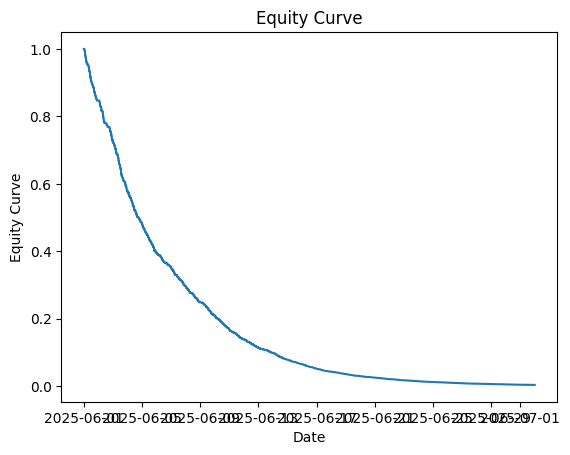

In [75]:
equity_curve = result.get('equity_curve')
plt.plot(equity_curve)
plt.xlabel('Date')
plt.ylabel('Equity Curve')
plt.title('Equity Curve')
plt.show()

In [76]:
print (result)

{'equity_curve': open_time
2025-06-01 00:01:00         NaN
2025-06-01 00:02:00    1.000000
2025-06-01 00:03:00    1.000000
2025-06-01 00:04:00    1.000000
2025-06-01 00:05:00    1.000000
                         ...   
2025-07-01 23:55:00    0.003913
2025-07-01 23:56:00    0.003913
2025-07-01 23:57:00    0.003913
2025-07-01 23:58:00    0.003913
2025-07-01 23:59:00    0.003913
Name: strategy_ret, Length: 44638, dtype: float64, 'total_return': np.float64(-0.9960873234647202), 'max_drawdown': -0.9960873234647202, 'sharpe_ratio': np.float64(-2.850423682868554), 'total_trades': 721}


In [77]:
for index in equity_curve:
    print(index)

nan
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
0.996
0.9964793438098861
0.996597582865039
0.9960115901064509
0.9963897744459378
0.9965524517702123
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.9929916307659689
0.99